### **Student Information**
GitHub ID: lakeofpeppi

Kaggle name: angeliemelisa

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**


## 1. Model Development (10 pts Required)


**Chart available on the cell below this.**


### 1.1 Preprocessing Steps

I started by combining three datasets, `final_posts.json` (tweet text), `data_identification.csv` (train/test identification), and `emotion.csv` (emotion labels), using `post_id` as the common key. After merging, I obtained 3,360 training samples and 1,440 test samples with no missing values, covering six emotion categories, where joy was the most common (875 samples) and fear was the least common (288 samples).

For the TF-IDF and Linear SVM baseline, I cleaned the text by converting it to lowercase, removing URLs and user mentions, and normalizing extra spaces. For the transformer models, I used lighter preprocessing by fixing curly quotation marks and replacing URLs with `http` and usernames with `@user`, while keeping capitalization and punctuation. I chose this approach because pretrained language models are designed to process more natural text, and features such as capital letters and exclamation marks can still provide useful information about emotions.


### 1.2 Feature Engineering Steps

For my Linear SVM baseline, I used `TfidfVectorizer` to convert the cleaned tweets into numerical features. I included both unigrams and bigrams (`ngram_range=(1,2)`) so the model could recognize individual words as well as short phrases like "not happy." I also set `min_df=2`, `max_df=0.95`, and `sublinear_tf=True`, which produced 7,439 features. TF-IDF was useful because it gives more weight to distinctive terms rather than words that appear frequently across many tweets. I fitted the vectorizer on the training data only and then applied it to the test data to avoid data leakage.

For the transformer models, I did not manually create TF-IDF features or word embeddings. Instead, I used each model's pretrained tokenizer to convert the tweets into token IDs, with a maximum sequence length of 128 tokens and padding within each batch. Since the `j-hartmann` models already have an emotion classification head covering anger, disgust, fear, joy, sadness, surprise, and neutral, I reused the existing outputs for the six competition emotions instead of initializing a new classification layer from scratch. This allowed the models to build on their previously learned emotion representations during fine-tuning.


### 1.3 Explanation of My Model

I started with a Linear SVM (`LinearSVC`) using TF-IDF features as my baseline model. I evaluated it using a 20% validation split, which resulted in an accuracy of 0.503 and a macro F1 of 0.485. Among the six emotions, disgust performed the worst, with an F1 of around 0.30. After correcting the Kaggle submission column from `post_id` to `id`, the baseline achieved a public F1 of 0.5659.

Since the baseline struggled to distinguish some emotions, I decided to try pretrained emotion classification models. I used `j-hartmann/emotion-english-distilroberta-base` and `j-hartmann/emotion-english-roberta-large`, which were already trained to recognize emotions in text. During fine-tuning, I used AdamW optimization, a linear learning-rate schedule with warmup, gradient clipping, and mild class weighting based on the square root of inverse class frequency. This was intended to give less frequent emotions more importance during training, since macro F1 considers every class equally.

For validation, I used a stratified 15% split containing 504 posts. DistilRoBERTa achieved a macro F1 of 0.6188 after four epochs and 0.6231 after two epochs, while RoBERTa-large achieved 0.6526 after four epochs. I also experimented with combining their predictions, and the best tested validation ensemble achieved a macro F1 of 0.6641.

For the ensemble, I averaged the six emotion probabilities produced by the two models and selected the emotion with the highest combined probability as the final prediction. The final submission code in my Colab notebook uses four epochs for both models, although the highest validation score came from combining the two-epoch DistilRoBERTa and four-epoch RoBERTa-large predictions.

My transformer ensemble achieved a **public Kaggle macro F1 of 0.6360**, which improved on the SVM baseline's public score of 0.5659. The public score was lower than my best local validation result, possibly because the validation set contained only 504 posts and might not fully represent the unseen competition data. The final private leaderboard result is provided in the ranking screenshot.


### 1.4 AI Prompts, What I Used and Why

Throughout this assignment, I used ChatGPT to help me explore different models and troubleshoot errors. However, I still checked the suggestions against my actual code and results before deciding whether to use them.

**1. Exploring transformer models**

**Prompt:** my tf-idf + linear svm only got around 0.485 macro f1 on validation. can we try a stronger model for emotion classification? maybe a pretrained transformer that can understand the context better?

**AI suggested:** Trying pretrained emotion-classification transformers after my TF-IDF and Linear SVM baseline achieved a validation macro F1 of 0.485.

I took the suggestion. I experimented with DistilRoBERTa and RoBERTa-large because the baseline struggled with several emotion classes. The transformer experiments achieved higher validation scores, with the best tested ensemble reaching 0.6641.

**2. Fixing the Kaggle submission error**

**Prompt:** kaggle says "ID column id not found" when i upload my submission.csv. what's wrong with my file and how do i fix it?

**AI suggested:** Changing the submission column name from `post_id` to `id` to match Kaggle's required format.

GPT was right, I checked the required submission format and corrected the CSV header, which allowed Kaggle to accept the submission.



The chart below compares the validation performance of the transformer configurations I tested. Although RoBERTa-large performed better than either DistilRoBERTa configuration individually, combining the models gave the highest validation macro F1 of 0.6641. This suggests that the ensemble benefited from combining their predictions, although the improvement over RoBERTa-large alone was relatively small.

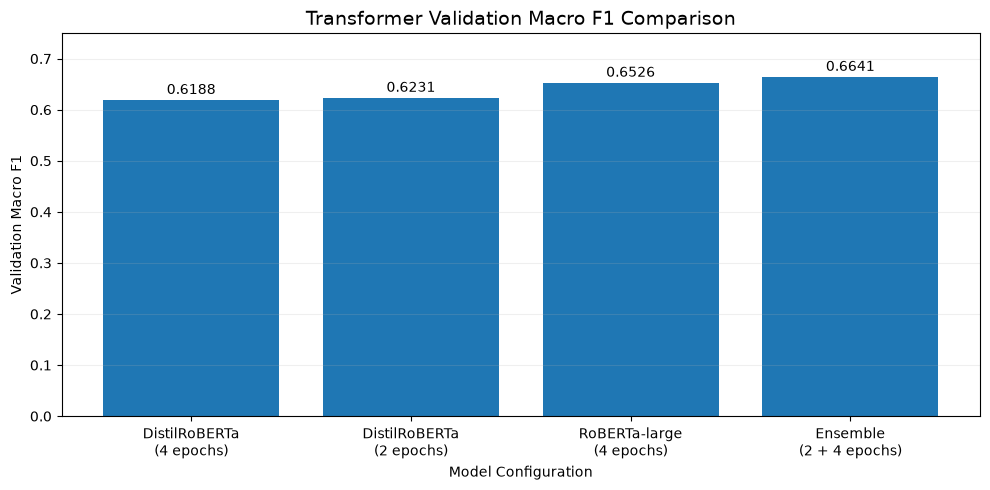

In [20]:

import matplotlib.pyplot as plt

models = [
    "DistilRoBERTa\n(4 epochs)",
    "DistilRoBERTa\n(2 epochs)",
    "RoBERTa-large\n(4 epochs)",
    "Ensemble\n(2 + 4 epochs)"
]

macro_f1 = [0.6188, 0.6231, 0.6526, 0.6641]

plt.figure(figsize=(10, 5))

bars = plt.bar(models, macro_f1)

plt.title("Transformer Validation Macro F1 Comparison", fontsize=14)
plt.ylabel("Validation Macro F1")
plt.xlabel("Model Configuration")
plt.ylim(0, 0.75)

for bar, score in zip(bars, macro_f1):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.012,
        f"{score:.4f}",
        ha="center",
        fontsize=10
    )

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# **Competition Code**

## 1. Preprocessing Steps

In [3]:

import os

# check the available files before loading the competition data
print("current folder:", os.getcwd())
print("data folder:", os.listdir("data"))


current folder: /work
data folder: ['embeddings', 'kaggle', '.ipynb_checkpoints', 'semeval']


In [4]:

import os

# Check that all Kaggle files are available
data_path = "data/kaggle"

print("Files found:")
for file in sorted(os.listdir(data_path)):
    print("-", file)


Files found:
- data_identification.csv
- emotion.csv
- final_posts.json
- sampleSubmission.csv


In [5]:

import pandas as pd
import json

# Load the competition files
data_info = pd.read_csv("data/kaggle/data_identification.csv")
emotion_data = pd.read_csv("data/kaggle/emotion.csv")
sample_submission = pd.read_csv("data/kaggle/sampleSubmission.csv")

with open("data/kaggle/final_posts.json", "r", encoding="utf-8") as f:
    posts_data = json.load(f)

# Check the structure of each dataset
print("Data identification:")
print(data_info.head())
print(data_info.shape)

print("\nEmotion labels:")
print(emotion_data.head())
print(emotion_data.shape)

print("\nSample submission:")
print(sample_submission.head())
print(sample_submission.shape)

print("\nJSON data type:", type(posts_data))
print("First JSON entry:")
if isinstance(posts_data, dict):
    first_key = next(iter(posts_data))
    print(first_key, posts_data[first_key])
elif isinstance(posts_data, list):
    print(posts_data[0])


Data identification:
   post_id    set
0  f8bv5zh  train
1  q0rr1l9  train
2  p94rwgk  train
3  9u6wtvm  train
4  h8ea329  train
(4800, 2)

Emotion labels:
   post_id    label
0  f8bv5zh  disgust
1  q0rr1l9  disgust
2  p94rwgk  sadness
3  9u6wtvm     fear
4  h8ea329     fear
(3360, 2)

Sample submission:
   post_id    label
0  xyzx9jp  sadness
1  l3vzzxt  sadness
2  g680iug  sadness
3  m4t8bp6  sadness
4  ai3al6e  sadness
(1440, 2)

JSON data type: <class 'list'>
First JSON entry:
{'post_id': 'f8bv5zh', 'text': 'Thought it looked weird as well.'}


In [6]:

# Convert the JSON posts into a DataFrame
posts_df = pd.DataFrame(posts_data)

# Combine post information with the actual text
full_data = data_info.merge(posts_df, on="post_id", how="left")

# Separate training and testing posts
train_data = full_data[full_data["set"] == "train"].copy()
test_data = full_data[full_data["set"] == "test"].copy()

# Add emotion labels to the training dataset only
train_data = train_data.merge(emotion_data, on="post_id", how="left")

# Check the results before preprocessing
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

print("\nMissing training labels:", train_data["label"].isna().sum())
print("Missing training text:", train_data["text"].isna().sum())
print("Missing testing text:", test_data["text"].isna().sum())

print("\nEmotion distribution:")
print(train_data["label"].value_counts())

print("\nTraining sample:")
print(train_data.head())


Training data: (3360, 4)
Testing data: (1440, 3)

Missing training labels: 0
Missing training text: 0
Missing testing text: 0

Emotion distribution:
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64

Training sample:
   post_id    set                                               text    label
0  f8bv5zh  train                   Thought it looked weird as well.  disgust
1  q0rr1l9  train                                 Bear died in a pit  disgust
2  p94rwgk  train                              I have endured worse.  sadness
3  9u6wtvm  train             The pottery around Brasov is in danger     fear
4  h8ea329  train  Meanwhile, our soldiers were approaching the a...     fear


In [7]:

import re

# Clean text while keeping useful emotion words
def clean_competition_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Apply the same preprocessing to training and testing data
train_data["clean_text"] = train_data["text"].apply(clean_competition_text)
test_data["clean_text"] = test_data["text"].apply(clean_competition_text)

# Compare original and cleaned text
print("Original:", train_data["text"].iloc[0])
print("Cleaned:", train_data["clean_text"].iloc[0])

print("\nEmpty training texts:", (train_data["clean_text"] == "").sum())
print("Empty testing texts:", (test_data["clean_text"] == "").sum())


Original: Thought it looked weird as well.
Cleaned: thought it looked weird as well.

Empty training texts: 0
Empty testing texts: 0


## 2. Feature Engineering Steps

In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert cleaned tweets into numerical features
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn vocabulary from training data only
X_train = tfidf_vectorizer.fit_transform(train_data["clean_text"])

# Apply the same vocabulary to testing data
X_test = tfidf_vectorizer.transform(test_data["clean_text"])

# Training labels
y_train = train_data["label"]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))


Training features: (3360, 7439)
Testing features: (1440, 7439)
Vocabulary size: 7439


## 3. Model Implementation Steps

In [9]:

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the labeled training data for validation
train_text, val_text, train_labels, val_labels = train_test_split(
    train_data["clean_text"],
    train_data["label"],
    test_size=0.2,
    random_state=42,
    stratify=train_data["label"]
)

# Fit TF-IDF only on the training portion
val_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_subtrain = val_vectorizer.fit_transform(train_text)
X_val = val_vectorizer.transform(val_text)

# Train the classifier
model = LinearSVC(random_state=42)
model.fit(X_subtrain, train_labels)

# Evaluate on unseen validation data
val_predictions = model.predict(X_val)

print("Validation accuracy:",
      round(accuracy_score(val_labels, val_predictions), 3))

print("Validation macro F1:",
      round(f1_score(val_labels, val_predictions, average="macro"), 3))

print("\nClassification Report:")
print(classification_report(val_labels, val_predictions))


Validation accuracy: 0.503
Validation macro F1: 0.485

Classification Report:
              precision    recall  f1-score   support

       anger       0.43      0.46      0.44       135
     disgust       0.32      0.27      0.30        91
        fear       0.67      0.42      0.52        57
         joy       0.55      0.67      0.61       175
     sadness       0.54      0.53      0.54       126
    surprise       0.54      0.49      0.51        88

    accuracy                           0.50       672
   macro avg       0.51      0.47      0.49       672
weighted avg       0.50      0.50      0.50       672



In [17]:
import pandas as pd

# Load the Kaggle submission file after uploading it to JupyterLab
df = pd.read_csv("data/kaggle/submission_tfidf_svm.csv")

print("Before:", df.columns.tolist())

# Rename the identifier column to match Kaggle's requirement
df = df.rename(columns={"post_id": "id"})

print("After:", df.columns.tolist())

# Save the corrected file
df.to_csv("submission_fixed.csv", index=False)

Before: ['post_id', 'label']
After: ['id', 'label']


In [16]:
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Missing values:", df.isnull().sum().sum())
print("Unique IDs:", df["id"].nunique())
print("IDs match:", set(df["id"]) == set(sample_submission["post_id"]))

Rows: 1440
Columns: ['id', 'label']
Missing values: 0
Unique IDs: 1440
IDs match: True


# Final Model; Transformer Fine-Tuning and Ensemble
This section was run in Google Colab on a T4 GPU and produced submission_transformer_fixed.csv (public F1 0.6360). It is not re-run here because training needs a GPU.

---

# **Final Model: Transformer Fine-Tuning and Ensemble**

The cells above are my TF-IDF + Linear SVM baseline. This section is the transformer approach that produced my final Kaggle submission, `submission_transformer_fixed.csv` (public macro F1 0.6360, private 0.6331).

I ran this part in Google Colab on a T4 GPU, since fine-tuning these models is way too slow on my laptop's CPU. So the cells here don't have saved outputs, and I didn't re-run them in this notebook. To reproduce it, open a GPU runtime in Colab, run `pip install -U transformers scikit-learn`, and upload the three competition files.

## 1. Preprocessing Steps: Transformer

Same three files joined on `post_id` as the baseline, but with lighter cleaning: curly quotes are normalized, links become `http` and usernames become `@user`. Everything else (casing, punctuation) is kept, because the pretrained models were trained on natural text and those cues can carry emotion.

In [ ]:
import json, re, random, numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

LABELS = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# load + join the three files on post_id
# in this repo the files live in data/kaggle/, in colab they were uploaded next to the notebook
from pathlib import Path
input_dir = Path('data/kaggle') if Path('data/kaggle/final_posts.json').exists() else Path('.')
posts = pd.DataFrame(json.load(open(input_dir / 'final_posts.json', encoding='utf-8')))
ids   = pd.read_csv(input_dir / 'data_identification.csv')
emo   = pd.read_csv(input_dir / 'emotion.csv')
df = posts.merge(ids, on='post_id').merge(emo, on='post_id', how='left')

# light cleaning: normalize fancy quotes, replace links/usernames with placeholders
def clean(t):
    t = t.replace('\u2019', "'").replace('\u201c', '"').replace('\u201d', '"')
    t = re.sub(r'http\S+', 'http', t)
    t = re.sub(r'@\w+', '@user', t)
    return t.strip()
df['text'] = df['text'].map(clean)

train = df[df.set == 'train'].reset_index(drop=True)
test  = df[df.set == 'test'].reset_index(drop=True)
print(len(train), 'train /', len(test), 'test')
print(train.label.value_counts())

## 2. Feature Engineering Steps: Tokenizer and Training Function

Instead of building features by hand, each model uses its own pretrained tokenizer (truncated at 128 tokens). The `run()` function below handles tokenizing, fine-tuning and predicting for any model name. Since the `j-hartmann` models already have an emotion output layer, it reuses the six outputs that match our labels instead of starting a new layer from scratch, and it uses mild class weights so smaller classes like fear still matter for macro F1.

In [ ]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run(model_name, train_df, pred_dfs, epochs=4, lr=2e-5, bs=16, max_len=128, seed=42, eval_df=None):
    """fine-tune model_name on train_df, return a list of (n, 6) prob arrays, one per df in pred_dfs"""
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name)

    # trick: j-hartmann emotion models already have anger/disgust/fear/joy/sadness/surprise (+neutral) heads.
    # if the model knows our labels, reuse its head instead of starting a new one from random
    l2i = {k.lower(): v for k, v in model.config.label2id.items()}
    if all(l in l2i for l in LABELS):
        cols = [l2i[l] for l in LABELS]
        print('reusing pretrained emotion head')
    else:
        model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(LABELS))
        cols = list(range(len(LABELS)))
    model.to(device)

    # mild class weights (sqrt of inverse freq) so fear/surprise aren't ignored -> helps macro f1
    counts = train_df.label.value_counts()
    w = torch.zeros(model.config.num_labels)
    for i, l in enumerate(LABELS):
        w[cols[i]] = (len(train_df) / (len(LABELS) * counts[l])) ** 0.5
    loss_fn = torch.nn.CrossEntropyLoss(weight=w.to(device))

    y_all = np.array([cols[LABELS.index(l)] for l in train_df.label])
    texts = train_df.text.tolist()

    def batches(txts, ys=None, shuffle=False):
        idx = list(range(len(txts)))
        if shuffle: random.shuffle(idx)
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            enc = tok([txts[j] for j in b], truncation=True, max_length=max_len, padding=True, return_tensors='pt')
            enc = {k: v.to(device) for k, v in enc.items()}
            yield enc, (torch.tensor(ys[b]).to(device) if ys is not None else None)

    @torch.no_grad()
    def predict(d):
        model.eval(); out = []
        for enc, _ in batches(d.text.tolist()):
            with torch.autocast('cuda', dtype=torch.float16, enabled=device == 'cuda'):
                logits = model(**enc).logits.float()
            out.append(torch.softmax(logits[:, cols], -1).cpu().numpy())  # keep only our 6 columns
        return np.concatenate(out)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * ((len(texts) + bs - 1) // bs)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler(enabled=device == 'cuda')

    for ep in range(epochs):
        model.train(); tot = 0
        for enc, yb in batches(texts, y_all, shuffle=True):
            with torch.autocast('cuda', dtype=torch.float16, enabled=device == 'cuda'):
                loss = loss_fn(model(**enc).logits.float(), yb)
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        msg = f'epoch {ep+1}: train loss {tot:.1f}'
        if eval_df is not None:
            p = predict(eval_df).argmax(1)
            msg += f' | val macro F1 {f1_score(eval_df.label, [LABELS[i] for i in p], average="macro"):.4f}'
        print(msg)

    outs = [predict(d) for d in pred_dfs]
    del model; torch.cuda.empty_cache()
    return outs

## 3. Model Implementation Steps: Validation and Ensemble

First I checked each model on a stratified 15% validation split (504 posts) to pick the number of epochs and the learning rate. The validation scores are the ones shown in the chart in my report.

In [ ]:
MODEL = 'j-hartmann/emotion-english-distilroberta-base'
tr, va = train_test_split(train, test_size=0.15, stratify=train.label, random_state=0)
(va_probs,) = run(MODEL, tr, [va], epochs=4, lr=3e-5, eval_df=va)
print(classification_report(va.label, [LABELS[i] for i in va_probs.argmax(1)], digits=3))

Then I trained both models on all 3,360 labeled posts, averaged their predicted probabilities for the six emotions, and picked the emotion with the highest average for each test post. This is the cell that wrote my submitted file.

In [ ]:
CONFIGS = [
    ('j-hartmann/emotion-english-distilroberta-base', 4, 3e-5),
    ('j-hartmann/emotion-english-roberta-large',      4, 1e-5),
]
all_probs = []
for name, ep, lr in CONFIGS:
    print('==', name)
    (p,) = run(name, train, [test], epochs=ep, lr=lr)
    all_probs.append(p)
    np.save(name.split('/')[-1] + '_test_probs.npy', p)  # saved so you can re-ensemble later without retraining

probs = np.mean(all_probs, axis=0)
# kaggle wants the column to be called id, not post_id (my first upload failed because of this)
sub = pd.DataFrame({'id': test.post_id, 'label': [LABELS[i] for i in probs.argmax(1)]})
sub.to_csv('submission_transformer_fixed.csv', index=False)
print(sub.shape); print(sub.label.value_counts()); sub.head()